<a href="https://colab.research.google.com/github/lya-karolini/pipp3-cancer-mama/blob/main/analise_cancer_mama.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
# Carregando os dados do seu GitHub e separando Treino/Teste
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, precision_recall_curve
)

# Lê o arquivo CSV direto do seu repositório no GitHub
url = "https://raw.githubusercontent.com/lya-karolini/pipp3-cancer-mama/main/dados_cancer_mama.csv"
df = pd.read_csv(url)

# Converte a coluna alvo: M (Maligno) vira 1 e B (Benigno) vira 0
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

# Separa as 30 características do exame (X) da resposta final (y)
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

# Divide em 70% treino e 30% teste mantendo a proporção de casos malignos (stratify=y)
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.3, random_state=29, stratify=y
)

print(f"Total de pacientes: {len(df)} | Treino: {len(Xtr)} | Teste: {len(Xte)}")
print(f"Taxa de casos malignos: {y.mean():.1%}")



Total de pacientes: 569 | Treino: 398 | Teste: 171
Taxa de casos malignos: 37.3%


Ponto de parada ideal: profundidade = 2

 profundidade  treino  validacao  distancia
            1   0.920      0.912      0.007
            2   0.955      0.953      0.002
            3   0.965      0.947      0.017
            5   0.992      0.947      0.045
            8   1.000      0.942      0.058
           15   1.000      0.942      0.058


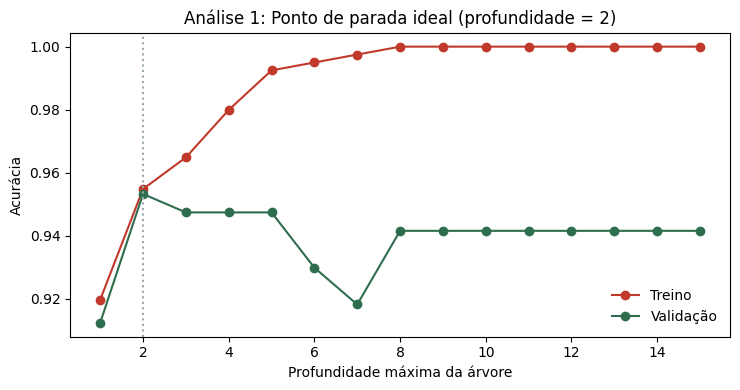

In [9]:
# Análise 1 — Sobreajuste (Overfitting) em Números

linhas = []
# Testa árvores com profundidade máxima de 1 até 15
for prof in range(1, 16):
    m = DecisionTreeClassifier(max_depth=prof, random_state=29).fit(Xtr, ytr)
    linhas.append({
        "profundidade": prof,
        "treino": accuracy_score(ytr, m.predict(Xtr)),
        "validacao": accuracy_score(yte, m.predict(Xte))
    })

curva = pd.DataFrame(linhas)
curva["distancia"] = curva["treino"] - curva["validacao"]
melhor_prof = int(curva.loc[curva["validacao"].idxmax(), "profundidade"])

print(f"Ponto de parada ideal: profundidade = {melhor_prof}\n")
print(curva.iloc[[0, 1, 2, 4, 7, 14]].round(3).to_string(index=False))

plt.figure(figsize=(7.5, 4))
plt.plot(curva.profundidade, curva.treino, marker="o", color="#C0392B", label="Treino")
plt.plot(curva.profundidade, curva.validacao, marker="o", color="#2E6E4E", label="Validação")
plt.axvline(melhor_prof, color="#9AA7AD", ls=":")
plt.xlabel("Profundidade máxima da árvore")
plt.ylabel("Acurácia")
plt.title(f"Análise 1: Ponto de parada ideal (profundidade = {melhor_prof})")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()



In [10]:
# Análise 2 — Validação Cruzada (5 Dobras)

modelos = {
    f"Árvore Podada (prof={melhor_prof})": DecisionTreeClassifier(max_depth=melhor_prof, random_state=29),
    "Árvore Sem Limite": DecisionTreeClassifier(random_state=29),
    "Random Forest (300)": RandomForestClassifier(n_estimators=300, random_state=29, n_jobs=-1)
}

for nome, mod in modelos.items():
    # Divide o treino em 5 partes e testa cada modelo 5 vezes
    scores = cross_val_score(mod, Xtr, ytr, cv=5, scoring="accuracy")
    print(f"{nome:25s} | Média: {scores.mean():.3f} | Desvio: {scores.std():.3f} | Dobras: {np.round(scores, 3)}")


Árvore Podada (prof=2)    | Média: 0.925 | Desvio: 0.040 | Dobras: [0.95  0.912 0.9   0.873 0.987]
Árvore Sem Limite         | Média: 0.922 | Desvio: 0.030 | Dobras: [0.95  0.938 0.875 0.899 0.949]
Random Forest (300)       | Média: 0.947 | Desvio: 0.041 | Dobras: [0.975 0.962 0.9   0.899 1.   ]


=== TABELA DE MÉTRICAS ===
                    Modelo  Acurácia  Precisão  Recall    F1
  Baseline (Chuta maioria)     0.626     0.000   0.000 0.000
      Random Forest Padrão     0.965     0.953   0.953 0.953
RF class_weight='balanced'     0.971     0.968   0.953 0.961

=== MATRIZ DE CONFUSÃO (RF PADRÃO) ===
                   Previu: Benigno (0)  Previu: Maligno (1)
Real: Benigno (0)                  104                    3
Real: Maligno (1)                    3                   61


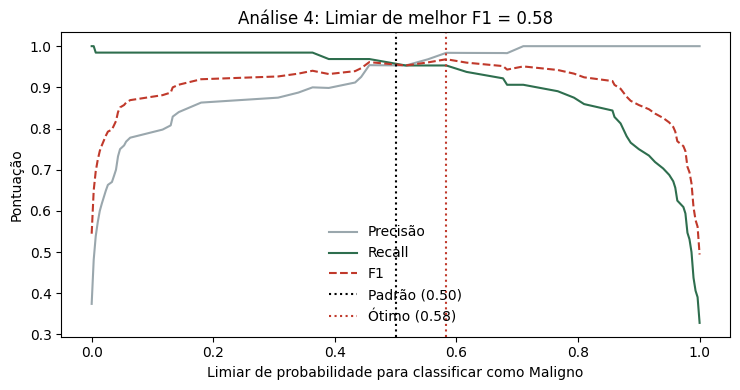

In [11]:
# Análises 3 e 4 — Desequilíbrio de Classes, Matriz de Confusão e Limiar

burro = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
rf_padrao = RandomForestClassifier(n_estimators=300, random_state=29, n_jobs=-1).fit(Xtr, ytr)
rf_pesada = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=29, n_jobs=-1).fit(Xtr, ytr)

def avaliar(mod, nome):
    pred = mod.predict(Xte)
    return {
        "Modelo": nome,
        "Acurácia": accuracy_score(yte, pred),
        "Precisão": precision_score(yte, pred, zero_division=0),
        "Recall": recall_score(yte, pred, zero_division=0),
        "F1": f1_score(yte, pred, zero_division=0)
    }

print("=== TABELA DE MÉTRICAS ===")
print(pd.DataFrame([
    avaliar(burro, "Baseline (Chuta maioria)"),
    avaliar(rf_padrao, "Random Forest Padrão"),
    avaliar(rf_pesada, "RF class_weight='balanced'")
]).round(3).to_string(index=False))

# Matriz de Confusão
mc = confusion_matrix(yte, rf_padrao.predict(Xte))
print("\n=== MATRIZ DE CONFUSÃO (RF PADRÃO) ===")
print(pd.DataFrame(mc, index=["Real: Benigno (0)", "Real: Maligno (1)"], columns=["Previu: Benigno (0)", "Previu: Maligno (1)"]))

# Gráfico de Ajuste de Limiar
prob = rf_padrao.predict_proba(Xte)[:, 1]
prec, rec, lim = precision_recall_curve(yte, prob)
f1 = np.divide(2*prec*rec, prec+rec, out=np.zeros_like(prec), where=(prec+rec) > 0)
otimo = lim[int(np.argmax(f1[:-1]))]

plt.figure(figsize=(7.5, 4))
plt.plot(lim, prec[:-1], color="#9AA7AD", label="Precisão")
plt.plot(lim, rec[:-1], color="#2E6E4E", label="Recall")
plt.plot(lim, f1[:-1], color="#C0392B", ls="--", label="F1")
plt.axvline(0.5, color="black", ls=":", label="Padrão (0.50)")
plt.axvline(otimo, color="#C0392B", ls=":", label=f"Ótimo ({otimo:.2f})")
plt.xlabel("Limiar de probabilidade para classificar como Maligno")
plt.ylabel("Pontuação")
plt.title(f"Análise 4: Limiar de melhor F1 = {otimo:.2f}")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()


=== TABELA DE VIÉS POR SUBGRUPO ===
                     Subgrupo   N  Prevalência  Recall  Precisão
Tumores Pequenos (<= mediana)  87        0.080   0.714     1.000
  Tumores Grandes (> mediana)  84        0.679   0.982     0.982
                        GERAL 171        0.374   0.953     0.984


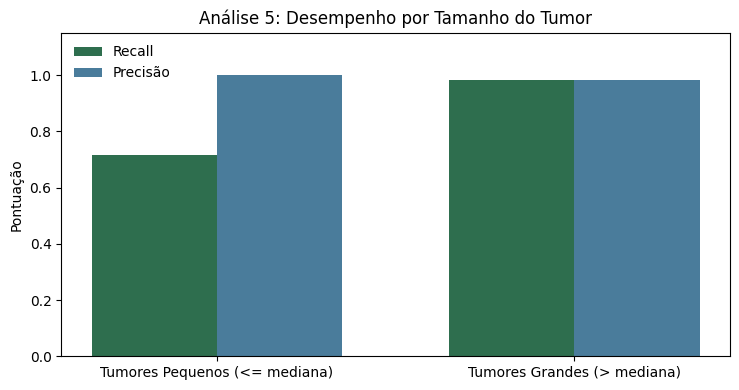

In [6]:
# Análise 5 — Viés por Subgrupo

# Separa os pacientes do teste pelo tamanho médio do tumor (mediana do radius_mean)
mediana_raio = Xtr["radius_mean"].median()
grupo_pequeno = Xte["radius_mean"] <= mediana_raio
grupo_grande = Xte["radius_mean"] > mediana_raio

pred_final = (prob >= otimo).astype(int)
grupos = {
    "Tumores Pequenos (<= mediana)": grupo_pequeno,
    "Tumores Grandes (> mediana)": grupo_grande
}

tabela_vies = pd.DataFrame([{
    "Subgrupo": nome,
    "N": int(m.sum()),
    "Prevalência": yte[m].mean(),
    "Recall": recall_score(yte[m], pred_final[m], zero_division=0),
    "Precisão": precision_score(yte[m], pred_final[m], zero_division=0)
} for nome, m in grupos.items()])

tabela_vies.loc[len(tabela_vies)] = [
    "GERAL", len(yte), yte.mean(),
    recall_score(yte, pred_final), precision_score(yte, pred_final)
]
print("=== TABELA DE VIÉS POR SUBGRUPO ===")
print(tabela_vies.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 4))
sub = tabela_vies.iloc[:2]
x = np.arange(len(sub))
largura = 0.35
ax.bar(x - largura/2, sub["Recall"], largura, label="Recall", color="#2E6E4E")
ax.bar(x + largura/2, sub["Precisão"], largura, label="Precisão", color="#4A7C9B")
ax.set_xticks(x)
ax.set_xticklabels(sub["Subgrupo"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Pontuação")
ax.set_title("Análise 5: Desempenho por Tamanho do Tumor")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
